In [2]:
import pandas as pd 
import numpy as np 

#Lecture du fichier et des informations 

df=pd.read_csv('stock_prices.csv')

print(df.head(-5))
print(df.shape)
print(df.info())

       symbol        date      open      high       low     close    volume
0         AAL  2014-01-02   25.0700   25.8200   25.0600   25.3600   8998943
1        AAPL  2014-01-02   79.3828   79.5756   78.8601   79.0185  58791957
2         AAP  2014-01-02  110.3600  111.8800  109.2900  109.7400    542711
3        ABBV  2014-01-02   52.1200   52.3300   51.5200   51.9800   4569061
4         ABC  2014-01-02   70.1100   70.2300   69.4800   69.8900   1148391
...       ...         ...       ...       ...       ...       ...       ...
497462   XLNX  2017-12-29   68.5000   68.7500   67.4000   67.4200    959640
497463     XL  2017-12-29   35.4500   35.4500   35.1600   35.1600   1017964
497464    XOM  2017-12-29   84.0000   84.2000   83.6400   83.6400   8523411
497465   XRAY  2017-12-29   66.3000   66.7200   65.7700   65.8300    917075
497466    XRX  2017-12-29   29.4000   29.4700   29.1200   29.1500   1537390

[497467 rows x 7 columns]
(497472, 7)
<class 'pandas.DataFrame'>
RangeIndex: 497472 ent

In [20]:
#Conversion en datetime de la colonne "date" qui était en string
df["date"]=pd.to_datetime(df["date"])
print(df.dtypes)
print(df.describe())

#Nombre de symboles
symbol_count=df['symbol'].nunique() 
print(symbol_count)

#Combien de lignes de données possède chaque action ?

print(df.groupby("symbol")["symbol"].value_counts())
print(df.groupby("symbol").size()) 

symbol               str
date      datetime64[us]
open             float64
high             float64
low              float64
close            float64
volume             int64
return           float64
dtype: object
                             date           open           high  \
count                      497472  497461.000000  497464.000000   
mean   2016-01-06 17:16:00.439984      86.352275      87.132562   
min           2014-01-02 00:00:00       1.620000       1.690000   
25%           2015-01-08 00:00:00      41.690000      42.090000   
50%           2016-01-11 00:00:00      64.970000      65.560000   
75%           2017-01-06 00:00:00      98.410000      99.230000   
max           2017-12-29 00:00:00    2044.000000    2067.990000   
std                           NaN     101.471228     102.312062   

                 low          close        volume         return  
count  497464.000000  497472.000000  4.974720e+05  496967.000000  
mean       85.552467      86.369082  4.253611e+0

In [21]:
#recherche de doublons car 505*1007 = 508 535 et ici on a 497 472 lignes
doublons=df.duplicated().sum()
doublons_date=df.duplicated(subset=["symbol", "date"]).sum()
print(doublons)
print(doublons_date)

print("Nombre de lignes :", len(df))
print("Nombre d'actions :", df["symbol"].nunique())
print("Total des observations par action :", df.groupby("symbol").size().sum())

#Cela veut dire que pas toutes les actions ont 1007 lignes donc il faut trouver le nombre qui ont en moins 

lignes_par_actions = df.groupby("symbol").size()
actions_incompletes = lignes_par_actions[lignes_par_actions < 1007]
print(actions_incompletes)

0
0
Nombre de lignes : 497472
Nombre d'actions : 505
Total des observations par action : 497472
symbol
APTV      18
BHF      117
BHGE     126
CFG      824
CSRA     535
DHR      995
DWDP      83
DXC      189
ES       997
EVHC     271
FTV      378
GOOG     949
HLT      250
HPE      555
HPQ      555
ICE     1006
INFO     891
KHC      629
NAVI     934
O        995
PYPL     629
QRVO     755
SYF      862
UA       438
WLTW     502
WRK      636
dtype: int64


In [7]:
# Nombre de lignes où le plus haut est inférieur au plus bas pour voir la cohérence des prix 
print((df["high"] < df["low"]).sum())
anomalie_difference=df[df["high"] < df["low"]]
print(anomalie_difference)

# Nombre de lignes où la clôture est hors de l'intervalle low-high
print(((df["close"] < df["low"])|(df["close"] > df["high"])).sum())
anomalie_intervalle=df[(df["close"] < df["low"])|(df["close"] > df["high"])]
print(anomalie_intervalle)

1
      symbol       date   open    high    low   close   volume
45501    AOS 2014-05-19  23.89  23.595  23.85  24.445  1944854
9
       symbol       date     open     high      low     close   volume
45501     AOS 2014-05-19   23.890   23.595   23.850   24.4450  1944854
48774     SPG 2014-05-28  176.230  176.600  174.500  165.4200  1383759
59618     CHK 2014-06-30   30.430   31.100   30.370   29.3900  8132836
60252      IP 2014-07-01   50.850   51.070   50.570   50.0900  5624981
79814       O 2014-08-27   44.675   44.700   44.660   44.5272   185518
269985    BBY 2016-03-14   33.550   33.750   33.080   32.7200  6037794
291756    WRK 2016-05-13   42.450   42.890   41.820   38.3900  2153541
293543    LNT 2016-05-19   35.190   35.785   35.085   17.8700  1231722
301166     UA 2016-06-10   35.750   36.410   35.700   35.5400   616887


In [8]:
#données triées
df = df.sort_values(by=["symbol", "date"],ascending=True)
print(df)

       symbol       date   open    high    low  close   volume
57          A 2014-01-02  57.10  57.100  56.15  56.21  1916160
540         A 2014-01-03  56.39  57.345  56.26  56.92  1866651
1023        A 2014-01-06  57.40  57.700  56.56  56.64  1777472
1506        A 2014-01-07  56.95  57.630  56.93  57.45  1463208
1989        A 2014-01-08  57.33  58.540  57.17  58.39  2659468
...       ...        ...    ...     ...    ...    ...      ...
495451    ZTS 2017-12-22  72.30  72.370  71.79  71.99  1345683
495956    ZTS 2017-12-26  72.40  72.550  71.90  72.34   792134
496461    ZTS 2017-12-27  72.59  72.690  72.25  72.45  1159771
496966    ZTS 2017-12-28  72.49  72.600  72.14  72.39   710499
497471    ZTS 2017-12-29  72.55  72.760  72.04  72.04  1704122

[497472 rows x 7 columns]


In [22]:
# Calcul des rendements journaliers des chacunes des actions

rendement=df.groupby("symbol")["close"].pct_change()
print(rendement)
print("Nombre de NaN :", rendement.isna().sum())
print("Nombre de rendements positifs :", (rendement >= 0).sum())
print("Nombre de rendements négatifs :", (rendement < 0).sum())

# Création colonne return pour conserver ces valeurs

df["return"]=rendement
print(df.head())

# Calcul de la volatilité des actions

volatilite = df.groupby("symbol")["return"].std()*100
print(volatilite)
print(volatilite.describe())

# Affichage des 10 plus gros rendements
top10=volatilite.sort_values(ascending=False).head(10)
print(top10)

57             NaN
540       0.012631
1023     -0.004919
1506      0.014301
1989      0.016362
            ...   
495451   -0.004012
495956    0.004862
496461    0.001521
496966   -0.000828
497471   -0.004835
Name: close, Length: 497472, dtype: float64
Nombre de NaN : 505
Nombre de rendements positifs : 262242
Nombre de rendements négatifs : 234725
     symbol       date   open    high    low  close   volume    return
57        A 2014-01-02  57.10  57.100  56.15  56.21  1916160       NaN
540       A 2014-01-03  56.39  57.345  56.26  56.92  1866651  0.012631
1023      A 2014-01-06  57.40  57.700  56.56  56.64  1777472 -0.004919
1506      A 2014-01-07  56.95  57.630  56.93  57.45  1463208  0.014301
1989      A 2014-01-08  57.33  58.540  57.17  58.39  2659468  0.016362
symbol
A       1.578743
AAL     2.238868
AAP     1.947149
AAPL    1.430893
ABBV    1.643618
          ...   
XYL     1.297466
YUM     1.722456
ZBH     1.366409
ZION    1.668854
ZTS     1.422600
Name: return, Length: 505, dt

In [ ]:
# 1. Trier les données dans l'ordre chronologique
df = df.sort_values(["symbol", "date"]).copy()

# 2. Calculer l'indice de richesse
df["wealth_index"] = (df.groupby("symbol")["return"].transform(lambda r: (1 + r.fillna(0)).cumprod()))

# 3. Trouver le sommet historique à chaque date
df["running_max"] = (df.groupby("symbol")["wealth_index"].cummax())

# 4. Calculer la baisse depuis ce sommet
df["drawdown"] = (df["wealth_index"] / df["running_max"] - 1)

# 5. Extraire la pire baisse de chaque action
max_drawdown = df.groupby("symbol")["drawdown"].min()

# 6. Afficher les 10 pires maximum drawdowns
print(max_drawdown.sort_values().head(10))

symbol
CHK     -0.949201
FCX     -0.904201
MRO     -0.838570
RRC     -0.833191
DISCK   -0.818430
DISCA   -0.817284
WMB     -0.816628
WYNN    -0.792297
UAA     -0.776945
UA      -0.768423
Name: drawdown, dtype: float64


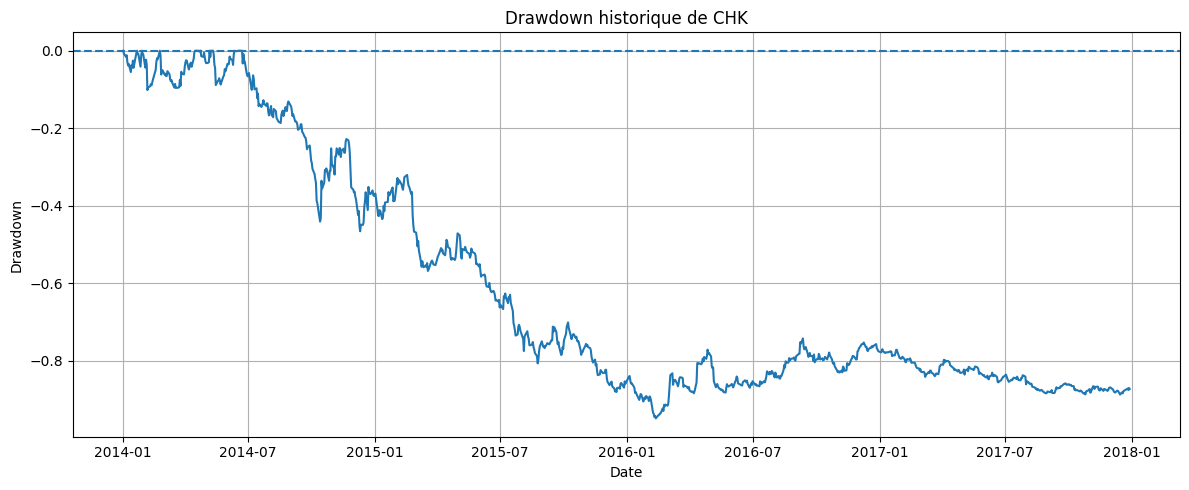

In [37]:
import matplotlib.pyplot as plt

# Sélectionner une action
ticker = "CHK"
stock = df[df["symbol"] == ticker].copy()

# Tracer le drawdown au cours du temps
plt.figure(figsize=(12, 5))
plt.plot(stock["date"], stock["drawdown"])

plt.title(f"Drawdown historique de {ticker}")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.axhline(y=0, linestyle="--")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
### Analyse du maximum drawdown de CHK 
# L'action CHK présente un maximum drawdown de −94,92 % sur la période étudiée. La baisse la plus importante se produit entre 2015 et 2016.
# Le drawdown ne revient pas à zéro avant la fin de 2017, ce qui indique que le précédent sommet n'a pas été retrouvé durant la période d'observation.
# Ce résultat met en évidence l'importance de mesurer non seulement la volatilité des rendements, mais également l'ampleur des pertes 
# et la durée pendant laquelle un actif reste sous son précédent sommet. L'interprétation doit toutefois tenir compte de la qualité et de l'ajustement des données de prix.